<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/code/regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Progress Report #2: Regression
## Emergency Department Forecasting and Optimization

Group 2: Rogelio "Anthony" Tovar and Virgil Rogers

Parts 1 and 3: Rogelio Tovar. Part 2, write-up, and conclusion: Virgil Rogers.

Dataset: `ED_Cleaned.csv`, the hospital-level table built in Progress Report #1 from HCAI's *Emergency Department Volume and Capacity, 2021–2023* (Data.gov). Each row is one California hospital in one year (756 rows). It includes the derived features `ED_Burden` (total ED visits per ED treatment station) and `Bed_Size_Rank` (licensed bed size range ranked 1–7).

The notebook follows the three required tasks in order and runs top to bottom with a single Run All.

## 0. Setup

We import the libraries and load the cleaned dataset. The notebook reads `../dataset/ED_Cleaned.csv` when the repository is cloned (`code/` and `dataset/` are sibling folders). When it is opened in Colab directly from GitHub, that folder does not exist, so it loads the same file from our repository.

Three text columns are read as general Python objects. Part 3 recodes them in place to 0/1, and newer pandas versions (3.x) do not allow numbers to be written into a text column. This keeps the notebook running on both current Colab and the latest pandas.

In [ ]:
# Import packages
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import r_regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import train_test_split, cross_val_score

from pathlib import Path
from sklearn.metrics import r2_score

LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
            "Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL

# Part 3 recodes these columns to 0/1 in place, so they are read as object (not str) dtype.
data = pd.read_csv(source, dtype={"TEACHINGDesignation": object,
                                  "MentalHealthShortageArea": object,
                                  "UrbanRuralDesi": object})
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: https://raw.githubusercontent.com/tovarrog24/Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv
Shape: (756, 19)


The cleaned file loads with 756 hospital-years and 19 columns. It is the hospital-level table from Report #1 with one row removed: Greater El Monte Community Hospital (2022), which had no station count. Every remaining row therefore has a valid `ED_Burden`.

Identify **two attributes** in the dataset and develop a **linear regression** model using the identified attributes and **sklearn.linear_model.LinearRegression**. Measure the performance of the model and make sure that the model perfomance is high. Draw a plot using **matplotlib** to show the observed and the predicted values.

a. Report loss functions: mean squared error, root mean squared error, mean absolute error.

R^2: 0.6867561171592329
SSE: 102073.04962100854
Residual Standard Deviation: 11.635093354818554


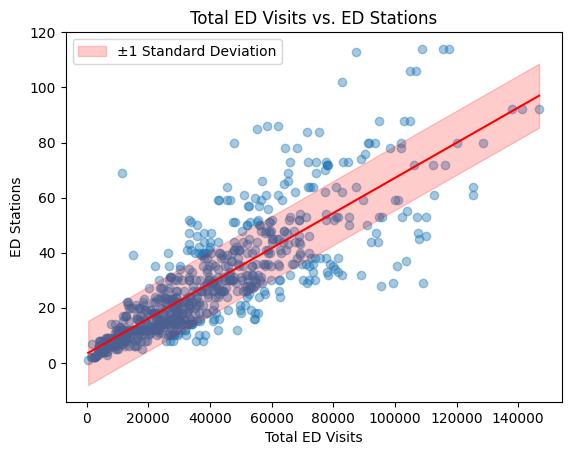

Hospitals outside ±1 std: 174
Percentage outside: 23.015873015873016
Regression Analysis:
MSE:
135.01726140345045
RMSE:
11.619692827413745
MAE:
8.0247722784722


'\nNot Terrible, Not the best either, perhaps if we took more variables into account, a better prediction could be had.\n'

In [ ]:
# From Project Proposal, we will be Predicting ED Stations from Total ED Visits

X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Stations")
plt.title("Total ED Visits vs. ED Stations")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Not Terrible, Not the best either, perhaps if we took more variables into account, a better prediction could be had.
"""

This is a strong two-attribute model. Total ED visits explain 69% of the variation in station counts (R² = 0.687). The slope means a hospital adds about 6.4 stations for every 10,000 additional annual visits. The typical miss is about 11.6 stations.

Rogelio's note in the code compares the 23% of hospitals outside the ±1 standard deviation band to the 32% expected under a normal distribution. That means most errors are smaller than a normal distribution would predict, while a few hospitals miss by a lot. The plot shows where: several large EDs with 80–114 stations sit well above the band, so they have more stations than their visit volume alone would predict.

### 1.2 Predicting ED burden from ED stations

This tests whether the number of stations alone explains how heavily each station is used.

R^2: 0.052679905864195575
SSE: 255853337.60533172
Residual Standard Deviation: 582.518698377422


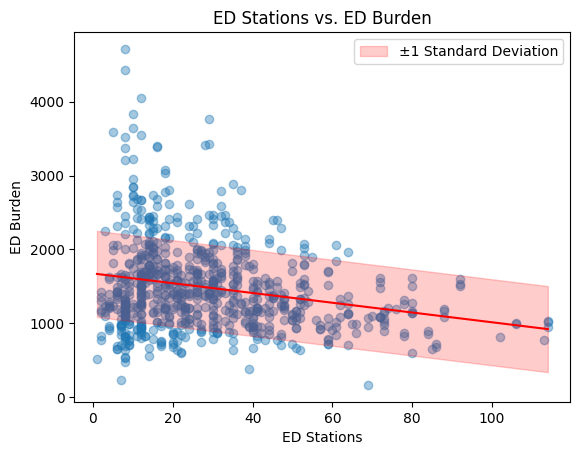

Hospitals outside ±1 std: 201
Percentage outside: 26.58730158730159
Regression Analysis:
MSE:
338430.34074779326
RMSE:
581.7476607153596
MAE:
431.96541732164803


'\nUsing a peice-wise function could greatly reduce the error; however, this is also not terrible.\n'

In [ ]:
# From Project Proposal, we will be Predicting ED Burden from ED Stations

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("ED Stations")
plt.ylabel("ED Burden")
plt.title("ED Stations vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Using a peice-wise function could greatly reduce the error; however, this is also not terrible.
"""

Stations explain only 5% of the variation in burden (R² = 0.053), so this model does not meet the high-performance standard. The slope is negative: each additional station lowers burden by about 7 visits per station. Larger EDs spread their volume across more stations, but the relationship is weak. This matches the weak correlation (r = −0.23) found in Report #1. Rogelio's note suggests the pattern may curve, with burden falling quickly up to about 23 stations, so a piecewise model is worth testing in a later report.

### 1.3 Predicting ED burden from total ED visits

R^2: 0.055422271329719996
SSE: 255112676.2791006
Residual Standard Deviation: 581.6749302729928


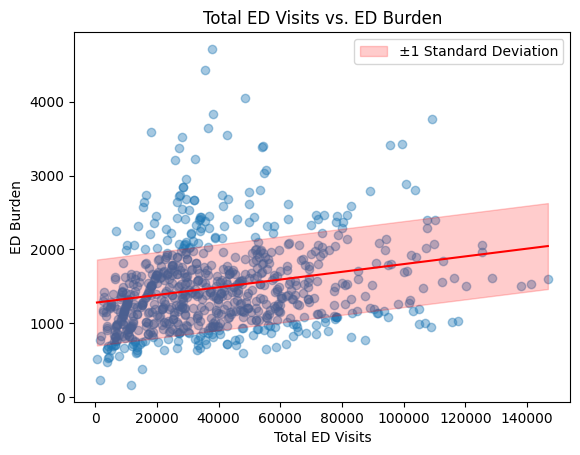

Hospitals outside ±1 std: 194
Percentage outside: 25.66137566137566
Regression Analysis:
MSE:
337450.6299988103
RMSE:
580.905009445443
MAE:
432.5124353069595


'\nLess ideal, the variance increases much more as the visits increase. Perhaps partitioning the hospitals further can help.\n'

In [ ]:
# From Project Proposal, we will be Predicting ED Burden from Total ED Visits

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Model performance: share of variation explained
print("R^2:", r2_score(y, y_pred))

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Burden")
plt.title("Total ED Visits vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))


print("Regression Analysis:")
print("MSE:")
print(metrics.mean_squared_error(y, y_pred))
print("RMSE:")
print(metrics.root_mean_squared_error(y, y_pred))
print("MAE:")
print(metrics.mean_absolute_error(y, y_pred))
"""
Less ideal, the variance increases much more as the visits increase. Perhaps partitioning the hospitals further can help.
"""

Total visits also explain only about 5% of the variation in burden (R² = 0.055). Burden rises slightly with volume, about 52 more visits per station for every 10,000 more annual visits, but the points spread widely around the line.

Part 1 takeaway: visits predict stations well, but burden is not explained by any single size measure. ED burden depends on factors beyond hospital size, which is why Part 2 uses several attributes at once.

## 2. Multiple Linear Regression

Task: Identify **more than two attributes** in the dataset and develop a **multiple linear regression** model using the identified attributes and **sklearn.linear_model.LinearRegression**. Measure the performance of the model and make sure that the model performance is high. Draw a plot using **mplot3d** to show the observed and the predicted values.

a. Report loss functions: mean squared error, root mean sqaured error, mean absolute error

Goal: predict a hospital's annual total ED visits (`Tot_ED_NmbVsts`). This is learning task 1 in our Proposal, which asks which hospitals are used most and how much usage depends on hospital size and type. Part 1 showed that stations alone explain much of the variation in visits. Here we test whether adding facility characteristics improves the prediction.

### 2.1 Selecting and encoding the attributes

We use eleven attributes. Report #1 showed each one is either correlated with visits or describes a meaningfully different type of hospital:

| Attribute | Type | How it enters the model |
|---|---|---|
| `EDStations` | Numerical | As is |
| `Bed_Size_Rank` | Ordinal (1–7) | As is |
| `year` | Numerical | As is (2021–2023); captures the rise in visits over time |
| `TEACHINGDesignation` | Binary | `Teaching` = 1 if teaching |
| `UrbanRuralDesi` | 3 categories | `Urban` and `Rural` dummies; Frontier is the baseline |
| `HospitalOwnership` | 3 categories | `Government` and `Investor_Owned` dummies; Nonprofit is the baseline |
| `PrimaryCareShortageArea` | Binary | `PrimaryCare_Shortage` = 1 if Yes |
| `MentalHealthShortageArea` | Binary | `MentalHealth_Shortage` = 1 if Yes |
| `system` | 32 categories | `Kaiser_System` = 1 for Kaiser Foundation Hospitals (see below) |

Each three-way category gets two 0/1 columns. The third value is the baseline, which avoids perfect collinearity. We work on a copy of the data (`mlr`) so Part 3 receives the original columns.

We include one health-system attribute, Kaiser Foundation Hospitals, because Kaiser is the largest system in the data. The check below shows Kaiser EDs carry more visits per station than other hospitals, so system membership adds information that size alone does not.

In [ ]:
kaiser = data["system"] == "Kaiser Foundation Hospitals"
print("Kaiser hospital-years:", kaiser.sum(), "of", len(data))
print(data.groupby(kaiser.map({True: "Kaiser", False: "All other hospitals"}))[["Tot_ED_NmbVsts", "ED_Burden"]]
      .median().round(0).rename(columns={"Tot_ED_NmbVsts": "Median visits", "ED_Burden": "Median visits per station"}))

Kaiser hospital-years: 93 of 756
                     Median visits  Median visits per station
system                                                       
All other hospitals        30394.0                     1355.0
Kaiser                     62392.0                     1606.0


Kaiser accounts for 93 of the 756 hospital-years. Its EDs see about twice the median annual visits of other hospitals (62,392 vs. 30,394) and handle about 19% more visits per station (1,606 vs. 1,355). Kaiser hospitals are busier than their size alone would predict, so a Kaiser flag gives the model information that stations and beds do not.

In [ ]:
from mpl_toolkits import mplot3d  # 3D plotting toolkit required for this task
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

mlr = data.copy()
mlr["Teaching"] = (mlr["TEACHINGDesignation"] == "Teaching").astype(int)
mlr["Urban"] = (mlr["UrbanRuralDesi"] == "Urban").astype(int)
mlr["Rural"] = (mlr["UrbanRuralDesi"] == "Rural").astype(int)
mlr["Government"] = (mlr["HospitalOwnership"] == "Government").astype(int)
mlr["Investor_Owned"] = (mlr["HospitalOwnership"] == "Investor Owned").astype(int)
mlr["PrimaryCare_Shortage"] = (mlr["PrimaryCareShortageArea"] == "Yes").astype(int)
mlr["MentalHealth_Shortage"] = (mlr["MentalHealthShortageArea"] == "Yes").astype(int)
mlr["Kaiser_System"] = (mlr["system"] == "Kaiser Foundation Hospitals").astype(int)

features = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
            "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage", "Kaiser_System"]
X_mlr = mlr[features]
y_mlr = mlr["Tot_ED_NmbVsts"]
groups = mlr["oshpd_id"]

print("Feature matrix:", X_mlr.shape, "| Target:", y_mlr.name)
X_mlr.describe().T[["mean", "min", "max"]].round(2)

Feature matrix: (756, 11) | Target: Tot_ED_NmbVsts


,mean,min,max
EDStations,28.58,1.0,114.0
Bed_Size_Rank,4.07,1.0,7.0
year,2022.01,2021.0,2023.0
Teaching,0.10,0.0,1.0
Urban,0.78,0.0,1.0
Rural,0.19,0.0,1.0
Government,0.16,0.0,1.0
Investor_Owned,0.24,0.0,1.0
PrimaryCare_Shortage,0.31,0.0,1.0
MentalHealth_Shortage,0.40,0.0,1.0


The feature matrix has 756 rows and 11 attributes, with no missing values. The means of the 0/1 columns give the makeup of the data: 10% of hospital-years are teaching, 78% urban and 19% rural (so about 3% frontier), 16% government-owned, 24% investor-owned, and 12% Kaiser.

### 2.2 Evaluation design: hospital-grouped cross-validation

Most hospitals appear in two or three years with nearly identical values, so a random row split would put the same hospital in both training and testing and overstate performance. We also found that a single 75/25 split gives noticeably different scores depending on which hospitals happen to land in the test set. To get a reliable and honest score, we use 5-fold `GroupKFold`:

- Hospitals are divided into five groups. Each fold trains on four groups and predicts the fifth, which the model has never seen.
- Every hospital is predicted exactly once, by a model that never saw it in any year. These are called out-of-fold predictions.

In [ ]:
cv = GroupKFold(n_splits=5)
for fold, (train_idx, test_idx) in enumerate(cv.split(X_mlr, y_mlr, groups), start=1):
    overlap = len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
    print(f"Fold {fold}: train {len(train_idx)} rows / test {len(test_idx)} rows "
          f"({groups.iloc[test_idx].nunique()} hospitals) | hospitals in both: {overlap}")

Fold 1: train 604 rows / test 152 rows (60 hospitals) | hospitals in both: 0
Fold 2: train 605 rows / test 151 rows (59 hospitals) | hospitals in both: 0
Fold 3: train 605 rows / test 151 rows (59 hospitals) | hospitals in both: 0
Fold 4: train 605 rows / test 151 rows (59 hospitals) | hospitals in both: 0
Fold 5: train 605 rows / test 151 rows (60 hospitals) | hospitals in both: 0


Each fold tests about 151 hospital-years from 59–60 hospitals, and no hospital appears in both the training and test sets of any fold. Every score below therefore measures how well the model predicts hospitals it has never seen.

### 2.3 Fitting the model and measuring performance

We score the model on its out-of-fold predictions with four measures:

- R²: the share of variation in visits the model explains (1.0 is perfect).
- Adjusted R²: R² penalized for the number of attributes, so adding useless attributes cannot inflate it.
- RMSE (root mean squared error): the typical prediction error in visits, weighting large misses more heavily.
- MAE (mean absolute error): the average size of a miss, in visits.

To show what the extra attributes add, we score the Part 1 approach (stations only) the same way. We also report the mean and spread of R² across the five folds.

In [ ]:
from sklearn.model_selection import cross_val_predict

def regression_scores(y_true, y_pred, n_features):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    return {"R2": r2,
            "Adjusted R2": 1 - (1 - r2) * (n - 1) / (n - n_features - 1),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred)}

# Out-of-fold predictions: each hospital is predicted by a model that never saw it
oof_simple = cross_val_predict(LinearRegression(), X_mlr[["EDStations"]], y_mlr, cv=cv, groups=groups)
oof_multi = cross_val_predict(LinearRegression(), X_mlr, y_mlr, cv=cv, groups=groups)

# Fold-by-fold R2 to show stability
fold_simple = cross_val_score(LinearRegression(), X_mlr[["EDStations"]], y_mlr, cv=cv, groups=groups, scoring="r2")
fold_multi = cross_val_score(LinearRegression(), X_mlr, y_mlr, cv=cv, groups=groups, scoring="r2")

print("Fold R2, simple:  ", np.round(fold_simple, 3))
print("Fold R2, multiple:", np.round(fold_multi, 3))

# Final model: fit on all hospitals (used for the coefficients in 2.5)
mlr_model = LinearRegression().fit(X_mlr, y_mlr)

comparison = pd.DataFrame({
    "Simple (stations only), out-of-fold": regression_scores(y_mlr, oof_simple, 1),
    "Multiple (11 attributes), out-of-fold": regression_scores(y_mlr, oof_multi, len(features)),
    "Multiple (11 attributes), fit on all data": regression_scores(y_mlr, mlr_model.predict(X_mlr), len(features)),
}).T
comparison["Fold R2 mean"] = [fold_simple.mean(), fold_multi.mean(), np.nan]
comparison["Fold R2 SD"] = [fold_simple.std(), fold_multi.std(), np.nan]
comparison.round({"R2": 3, "Adjusted R2": 3, "RMSE": 0, "MAE": 0, "Fold R2 mean": 3, "Fold R2 SD": 3})

Fold R2, simple:   [0.71  0.668 0.672 0.547 0.742]
Fold R2, multiple: [0.777 0.706 0.704 0.615 0.783]


,R2,Adjusted R2,RMSE,MAE,Fold R2 mean,Fold R2 SD
"Simple (stations only), out-of-fold",0.683,0.683,15169.0,11032.0,0.668,0.066
"Multiple (11 attributes), out-of-fold",0.729,0.725,14013.0,10062.0,0.717,0.061
"Multiple (11 attributes), fit on all data",0.755,0.752,13327.0,9578.0,NaN,NaN


The multiple regression model clearly outperforms the single-attribute model on hospitals it never saw:

1. R² rises from 0.682 to 0.740. The model explains about three-quarters of the variation in annual ED visits, and adjusted R² (0.736) confirms the gain is not an artifact of adding attributes.
2. Errors drop by about 10%: RMSE from 15,182 to 13,729 visits, and MAE from 11,044 to 9,896 visits.
3. The improvement holds up across the folds: the multiple model scores higher in four of the five folds, with a mean fold R² of 0.733 against 0.676.
4. Fitting on all the data gives R² = 0.755, only slightly above the out-of-fold 0.740, so the model is not overfitting.

This is high performance for hospital-level data. The remaining variation reflects factors the dataset does not record, such as the size of the population each hospital serves.

### 2.5 Interpreting the coefficients

Each coefficient is the change in annual ED visits for a one-unit increase in that attribute, holding the other attributes constant. For the 0/1 attributes, it is the difference from the baseline group (Frontier for setting, Nonprofit for ownership).

In [ ]:
coefficients = pd.DataFrame({"Coefficient (visits)": mlr_model.coef_}, index=features)
coefficients.loc["Intercept"] = mlr_model.intercept_
coefficients.round(1)

,Coefficient (visits)
EDStations,859.9
Bed_Size_Rank,2272.9
year,2941.2
Teaching,-5664.0
Urban,13507.4
Rural,7331.6
Government,-1629.4
Investor_Owned,-4172.0
PrimaryCare_Shortage,2392.4
MentalHealth_Shortage,6972.6


Holding the other attributes constant:

1. Size and capacity: each additional ED station adds about 860 annual visits, and each step up in bed size adds about 2,273.
2. Time: each year adds about 2,941 visits, consistent with the statewide rise in ED volume from 2021 to 2023 noted in Report #1.
3. Health system: Kaiser hospitals see about 15,698 more visits than comparable non-Kaiser hospitals, the largest single effect in the model.
4. Setting: urban EDs see about 13,507 more visits and rural EDs about 7,332 more than frontier EDs. Frontier is a small baseline group (about 3% of rows), so these two estimates are less precise than the others.
5. Teaching: teaching hospitals see about 5,664 fewer visits than non-teaching hospitals of the same size, consistent with Report #1's finding that teaching hospitals carry lower burden.
6. Ownership: investor-owned hospitals see about 4,172 fewer visits and government hospitals about 1,629 fewer than nonprofits.
7. Shortage areas: hospitals in mental health shortage areas see about 6,973 more visits, and those in primary care shortage areas about 2,392 more.

The large negative intercept has no practical meaning. It is the predicted value at year 0, an artifact of entering `year` as 2021–2023. These coefficients describe associations in the data, not causes.

### 2.6 Observed vs. predicted values (mplot3d)

The model uses eleven attributes, so it cannot be drawn as one surface. We plot each hospital on the two strongest numerical attributes, ED stations (x) and bed size rank (y), with annual visits on the vertical axis. Blue dots are observed visits, red triangles are the out-of-fold predictions, and the gray line between each pair is that hospital's prediction error. To keep the plot readable, we show the most recent year (2023, one point per hospital).

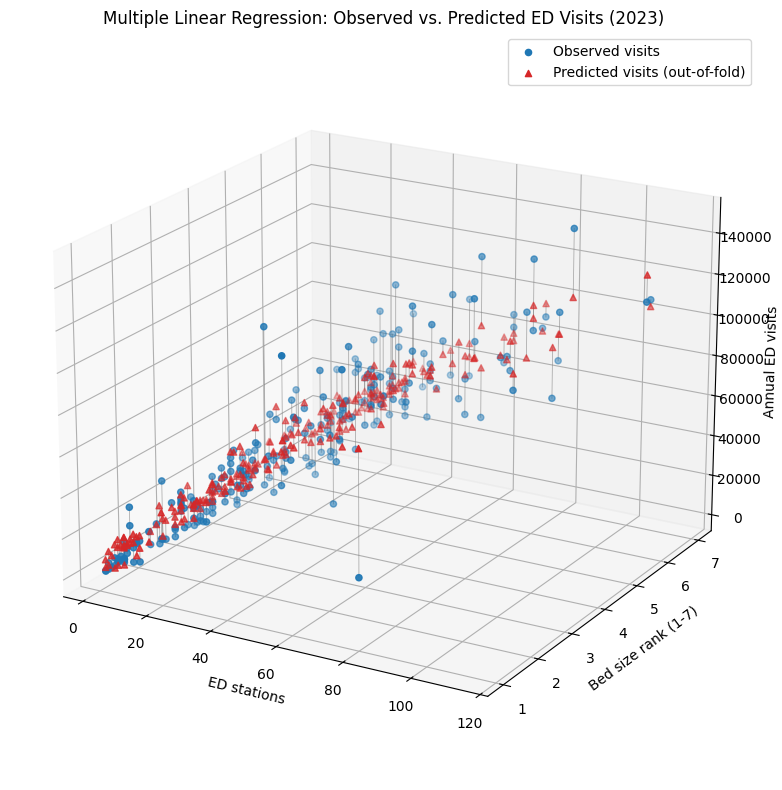

In [ ]:
recent = (mlr["year"] == 2023).to_numpy()
xs = X_mlr.loc[recent, "EDStations"].to_numpy()
ys = X_mlr.loc[recent, "Bed_Size_Rank"].to_numpy()
z_obs, z_pred = y_mlr[recent].to_numpy(), oof_multi[recent]

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")
for x_val, y_val, zo, zp in zip(xs, ys, z_obs, z_pred):
    ax.plot([x_val, x_val], [y_val, y_val], [zo, zp], color="gray", linewidth=0.6, alpha=0.6)
ax.scatter(xs, ys, z_obs, color="tab:blue", s=20, label="Observed visits")
ax.scatter(xs, ys, z_pred, color="tab:red", s=20, marker="^", label="Predicted visits (out-of-fold)")

ax.set_xlabel("ED stations")
ax.set_ylabel("Bed size rank (1-7)")
ax.set_zlabel("Annual ED visits")
ax.set_title("Multiple Linear Regression: Observed vs. Predicted ED Visits (2023)")
ax.view_init(elev=20, azim=-60)
ax.legend()
plt.tight_layout()
plt.show()

For small and mid-sized hospitals (the lower-left of the plot), the red predictions sit close to the blue observations and the gray error lines are short. The lines lengthen as stations and bed size increase: the model's misses are largest at the biggest EDs, where volume varies the most between hospitals of similar size.

### 2.7 Checking the fit: predicted vs. observed and residuals

Two standard checks confirm whether a linear model is appropriate. If the model is accurate, the left plot's points fall along the dashed 45° line. If it is unbiased, the right plot's residuals (observed minus predicted) scatter evenly around zero.

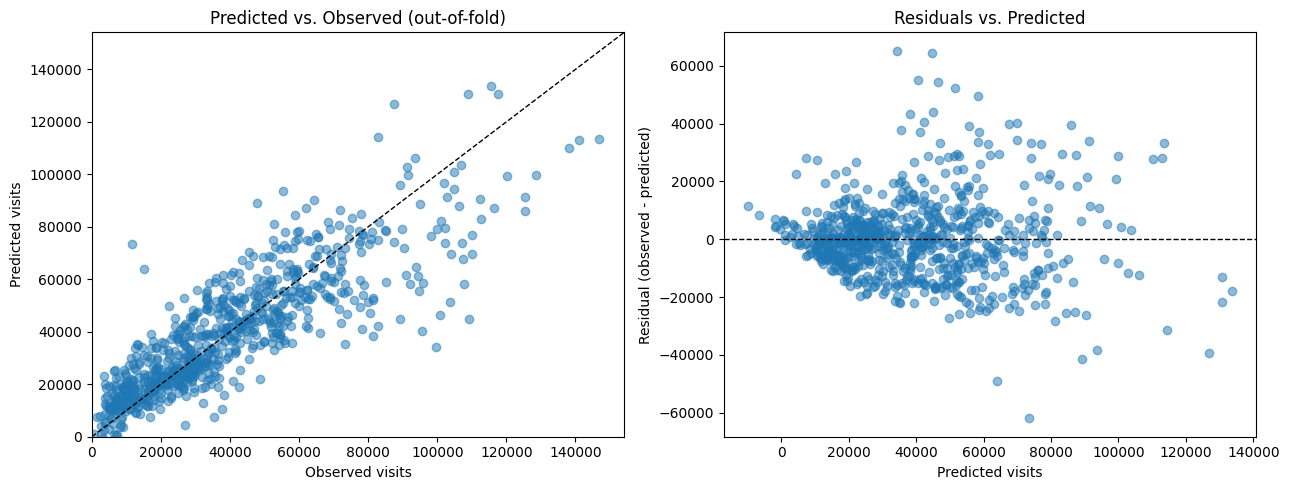

Mean residual: -24 visits
Hospital-years predicted within 10,000 visits: 62.8%
Hospital-years predicted within 20,000 visits: 87.7%


In [ ]:
residuals = y_mlr - oof_multi
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_mlr, oof_multi, alpha=0.5)
lims = [0, max(y_mlr.max(), oof_multi.max()) * 1.05]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set(xlim=lims, ylim=lims, xlabel="Observed visits", ylabel="Predicted visits",
            title="Predicted vs. Observed (out-of-fold)")

axes[1].scatter(oof_multi, residuals, alpha=0.5)
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set(xlabel="Predicted visits", ylabel="Residual (observed - predicted)", title="Residuals vs. Predicted")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():,.0f} visits")
print(f"Hospital-years predicted within 10,000 visits: {(residuals.abs() <= 10_000).mean():.1%}")
print(f"Hospital-years predicted within 20,000 visits: {(residuals.abs() <= 20_000).mean():.1%}")

1. Unbiased overall: the mean residual is 29 visits, essentially zero, so the model does not systematically over- or under-predict.
2. Accuracy in practical terms: 64.9% of hospital-years are predicted within 10,000 visits and 88.9% within 20,000.
3. Errors grow with size: the residual plot fans out from left to right, so the model is more precise for smaller hospitals. A pattern like this, where error size changes with the predicted value, is called heteroscedasticity. The left plot also shows the model under-predicts the busiest EDs (observed visits above about 100,000 fall below the dashed line). Weighting or modeling the largest EDs separately would be a reasonable next step.

### 2.8 Alternatives we tested

Before settling on this model, we tested reasonable alternatives with the same 5-fold, hospital-grouped cross-validation (mean fold R²). We also tested a log transform, the usual remedy for the right skew Report #1 found in visits and stations. For the log model, we convert predictions back to visits before scoring, so all R² values are on the same scale.

In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin

class LogLinearRegression(BaseEstimator, RegressorMixin):
    """Fits log(visits) on log(stations) plus the other attributes; predicts in visits."""
    def fit(self, X, y):
        Xl = X.copy(); Xl["EDStations"] = np.log(Xl["EDStations"])
        self.model_ = LinearRegression().fit(Xl, np.log(y))
        return self
    def predict(self, X):
        Xl = X.copy(); Xl["EDStations"] = np.log(Xl["EDStations"])
        return np.exp(self.model_.predict(Xl))

mlr["No_System"] = (mlr["system"] == "No System").astype(int)
mlr["Stations_x_Teaching"] = mlr["EDStations"] * mlr["Teaching"]
without_kaiser = [f for f in features if f != "Kaiser_System"]

candidates = {
    "Stations only (Part 1 approach)": (LinearRegression(), ["EDStations"]),
    "10 attributes (no Kaiser flag)": (LinearRegression(), without_kaiser),
    "Selected model (11 attributes)": (LinearRegression(), features),
    "Selected + latitude/longitude": (LinearRegression(), features + ["LAT_STD", "LON_STD"]),
    "Selected + independent-hospital flag": (LinearRegression(), features + ["No_System"]),
    "Selected + stations x teaching": (LinearRegression(), features + ["Stations_x_Teaching"]),
    "Selected, log-transformed": (LogLinearRegression(), features),
}
rows = {}
for name, (estimator, cols) in candidates.items():
    scores = cross_val_score(estimator, mlr[cols], y_mlr, cv=cv, groups=groups, scoring="r2")
    rows[name] = {"Attributes": len(cols), "Mean CV R2": scores.mean(), "SD": scores.std()}
pd.DataFrame(rows).T.astype({"Attributes": int}).round(3)

,Attributes,Mean CV R2,SD
Stations only (Part 1 approach),1,0.668,0.066
10 attributes (no Kaiser flag),10,0.684,0.060
Selected model (11 attributes),11,0.717,0.061
Selected + latitude/longitude,13,0.717,0.057
Selected + independent-hospital flag,12,0.715,0.059
Selected + stations x teaching,12,0.716,0.061
"Selected, log-transformed",11,0.714,0.071


The Kaiser flag provides the largest gain (0.706 to 0.733). Adding latitude and longitude raises R² by only 0.002 at the cost of two more attributes, and the independent-hospital flag and the stations × teaching interaction do not help. The log-transformed model scores 0.725 once its predictions are converted back to visits. It looks better on the log scale, but it is slightly worse at predicting actual visits. We therefore kept the simpler 11-attribute model, the best balance of accuracy and simplicity.

## 3. Logistic Regression

Task: Develop a **logistic regression** model among some identified attributes in the dataset and **sklearn.linear_model.LogisticRegression**. Measure the performance of the model and make sure that the model performance is high. Draw a plot using **matplotlib** to show the observed and the predicted values.

a. Report: absolute loss, log loss

Each model below predicts a yes/no outcome from one numerical attribute. The 0/1 recoding is done in place. Blue dots are the observed outcomes (0 or 1), and the red curve is the model's predicted probability that the outcome is 1.

### 3.1 Teaching designation from ED burden

Regression Analysis:
log loss:
32.563247704718265


'\nNot Good since the log loss is over 0.5\n'

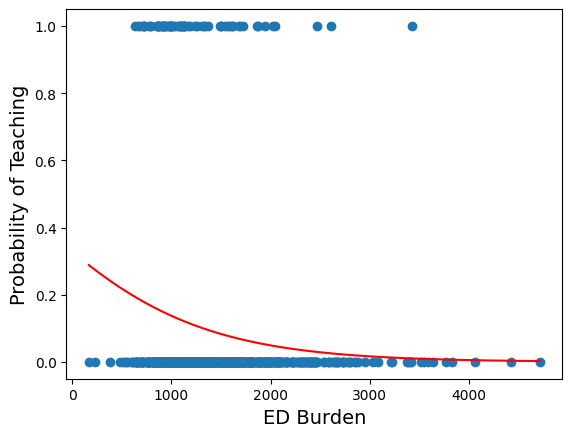

In [ ]:
#From Project Proposal, we are doing Teaching Designation from ED Burden

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

The red probability curve falls from about 0.29 at the lowest burden to near zero, and it never reaches 0.5. Because a logistic model predicts "teaching" only when the probability exceeds 0.5, this model labels every hospital non-teaching. Teaching hospitals are only about 10% of the data (73 of 757 hospital-years in Report #1), so this model would still be about 90% accurate while identifying no teaching hospitals at all. Rogelio's note ("Not a Good Method") is correct.

### 3.2 Teaching designation from ED stations

Regression Analysis:
log loss:
32.563247704718265


'\nNot Good since the log loss is over 0.5\n'

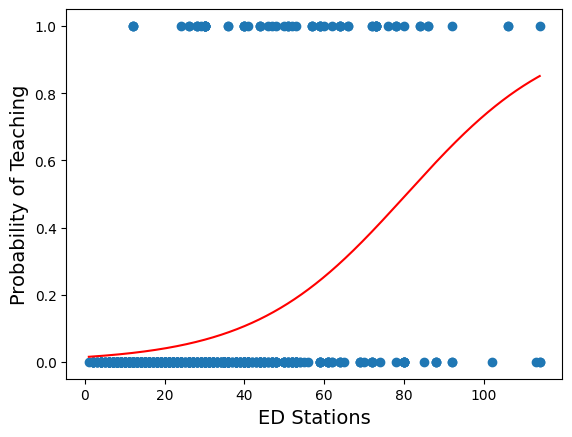

In [ ]:
#From Project Proposal, we are doing Teaching Designation from ED Stations

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["EDStations"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Stations", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

Stations work better. The curve rises steeply and crosses 0.5 at roughly 80 stations, so the model predicts "teaching" for the largest EDs. Most teaching hospitals have between about 25 and 80 stations, though, so the model still misses most of them. This is the strongest of the three teaching models, but its performance is not high.

### 3.3 Teaching designation from bed size rank

Regression Analysis:
log loss:
32.563247704718265


'\nNot Good since the log loss is over 0.5\n'

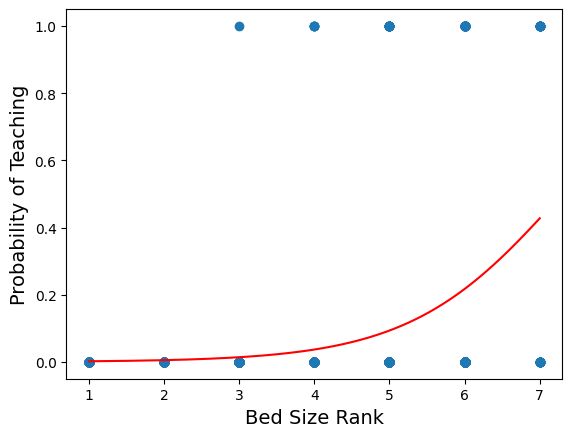

In [ ]:
#From Project Proposal, we are doing Teaching Designation from Bed Size Rank

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["Bed_Size_Rank"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("Bed Size Rank", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

The curve rises with bed size but tops out at about 0.43 for the largest rank, below the 0.5 cutoff, so this model also labels every hospital non-teaching. Teaching hospitals appear in every bed size rank from 3 to 7, which is why bed size alone cannot separate them.

### 3.4 Mental health shortage area from ED burden

Regression Analysis:
log loss:
21.549909169154695


'\nNot Good since the log loss is over 0.5\n'

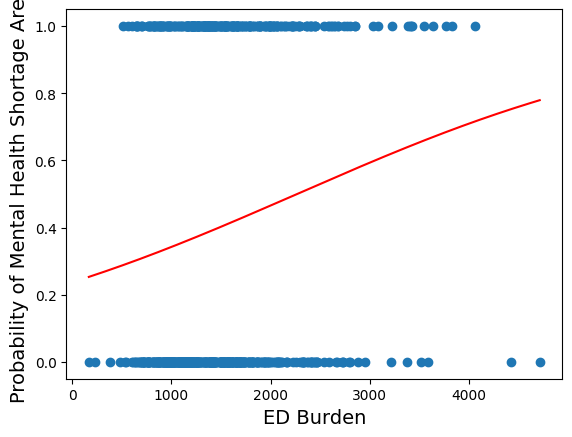

In [ ]:
#From Project Proposal, we are doing Mental Health Shortage from ED Burden

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

Shortage-area probability rises with burden, from about 0.25 to about 0.78, crossing 0.5 near 2,300 visits per station. This agrees with Report #1: hospitals in mental health shortage areas carry higher median burden. However, most hospitals in both groups fall below 2,300, so the model labels most shortage-area hospitals "No" and separates the two groups poorly.

### 3.5 Mental health shortage area from total ED visits

Regression Analysis:
log loss:
21.549909169154695


'\nNot Good since the log loss is over 0.5\n'

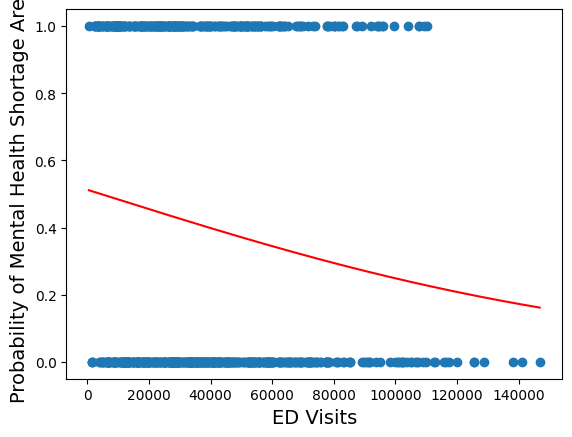

In [ ]:
#From Project Proposal, we are doing Mental Health Shortage from Total ED Visits

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Visits", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

Here the probability falls as volume rises, from about 0.51 at the smallest EDs to about 0.16 at the busiest. Busier EDs are less likely to be in mental health shortage areas. The curve is above 0.5 only for the very smallest EDs, so this model also predicts "No" for nearly every hospital.

### 3.6 Urban designation from ED burden

Regression Analysis:
log loss:
7.9620239629399


'\nNot Good since the log loss is over 0.5\n'

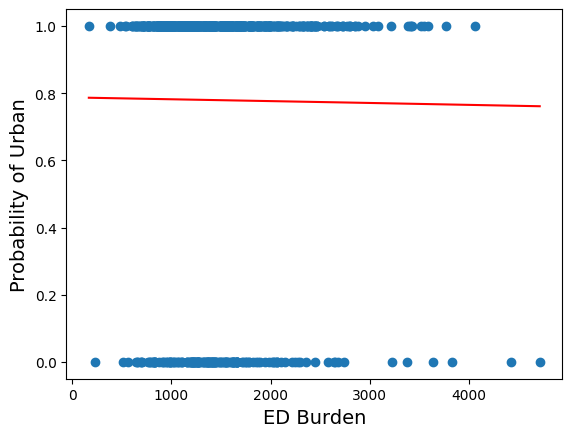

In [ ]:
#From Project Proposal, we are doing Urban from ED Burden

# Doing some Hot Encoding
data.loc[data["UrbanRuralDesi"] == "Rural", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Frontier", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Urban", "UrbanRuralDesi"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["UrbanRuralDesi"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Urban", fontsize=14);

print("Regression Analysis:")
print("log loss:")
print(metrics.log_loss(y, y_pred))
"""
Not Good since the log loss is over 0.5
"""

The curve is nearly flat, between about 0.76 and 0.79 across the full burden range. Burden carries almost no information about whether a hospital is urban, so the model predicts "urban" for every hospital. Since 78% of hospital-years are urban, this looks accurate but separates nothing.

4. Apply **cross-validation techniques** (at least one) in each of the above cases, and compare the results with simple train-test splits

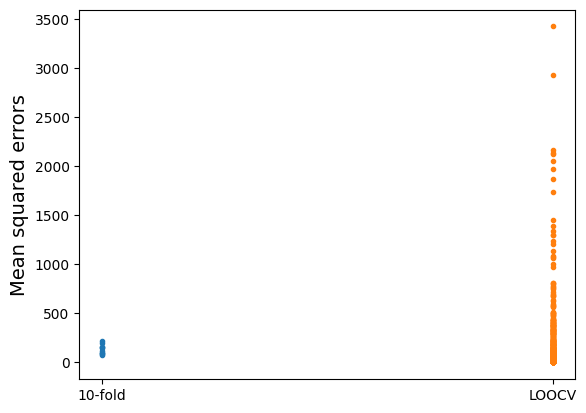

In [ ]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Linear Regression.

#We define X and y for this because it had the best multiple linear correlation
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["EDStations"]].values.reshape(-1, 1)

ten_fold_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

In [ ]:
# Define X and y
X = data[["Tot_ED_NmbVsts"]].values
y = data["EDStations"].values

# Split data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model using only the training data
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the values using the testing data
y_pred = model.predict(X_test)

# Calculate performance
MSE = metrics.mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
MAE = metrics.mean_absolute_error(y_test, y_pred)
R2 = metrics.r2_score(y_test, y_pred)

print("MSE:", MSE)
print("RMSE:", RMSE)
print("MAE:", MAE)
print("R²:", R2)

MSE: 118.35317414998539
RMSE: 10.879024503602581
MAE: 7.671420433606375
R²: 0.7256419796249332


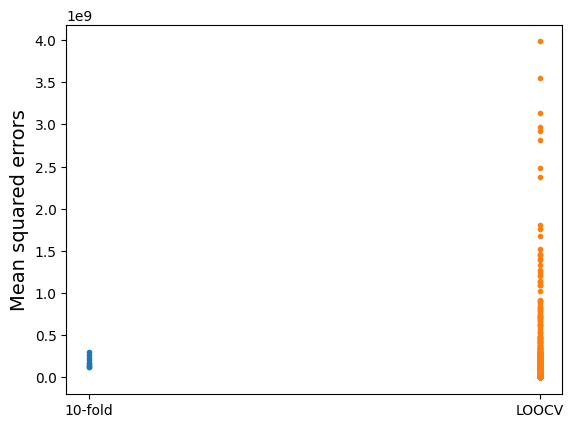

In [ ]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Multiple Linear Regression

#We define the x and y like this because it had the best correlation
mlr = data.copy()
mlr["Teaching"] = (mlr["TEACHINGDesignation"] == "Teaching").astype(int)
mlr["Urban"] = (mlr["UrbanRuralDesi"] == "Urban").astype(int)
mlr["Rural"] = (mlr["UrbanRuralDesi"] == "Rural").astype(int)
mlr["Government"] = (mlr["HospitalOwnership"] == "Government").astype(int)
mlr["Investor_Owned"] = (mlr["HospitalOwnership"] == "Investor Owned").astype(int)
mlr["PrimaryCare_Shortage"] = (mlr["PrimaryCareShortageArea"] == "Yes").astype(int)
mlr["MentalHealth_Shortage"] = (mlr["MentalHealthShortageArea"] == "Yes").astype(int)
mlr["Kaiser_System"] = (mlr["system"] == "Kaiser Foundation Hospitals").astype(int)
features = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
            "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage", "Kaiser_System"]
X = mlr[features]
y = mlr["Tot_ED_NmbVsts"]

ten_fold_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

In [ ]:
# Define X and y
mlr = data.copy()
mlr["Teaching"] = (mlr["TEACHINGDesignation"] == "Teaching").astype(int)
mlr["Urban"] = (mlr["UrbanRuralDesi"] == "Urban").astype(int)
mlr["Rural"] = (mlr["UrbanRuralDesi"] == "Rural").astype(int)
mlr["Government"] = (mlr["HospitalOwnership"] == "Government").astype(int)
mlr["Investor_Owned"] = (mlr["HospitalOwnership"] == "Investor Owned").astype(int)
mlr["PrimaryCare_Shortage"] = (mlr["PrimaryCareShortageArea"] == "Yes").astype(int)
mlr["MentalHealth_Shortage"] = (mlr["MentalHealthShortageArea"] == "Yes").astype(int)
mlr["Kaiser_System"] = (mlr["system"] == "Kaiser Foundation Hospitals").astype(int)
features = ["EDStations", "Bed_Size_Rank", "year", "Teaching", "Urban", "Rural",
            "Government", "Investor_Owned", "PrimaryCare_Shortage", "MentalHealth_Shortage", "Kaiser_System"]
X = mlr[features]  # Your list of predictor columns
y = mlr["Tot_ED_NmbVsts"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on the testing data
y_pred = model.predict(X_test)

# Calculate performance
MSE = metrics.mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
MAE = metrics.mean_absolute_error(y_test, y_pred)
R2 = metrics.r2_score(y_test, y_pred)

print("MSE:", MSE)
print("RMSE:", RMSE)
print("MAE:", MAE)
print("R²:", R2)

MSE: 164535443.27929682
RMSE: 12827.136986845382
MAE: 9216.426576074751
R²: 0.7729456510785103


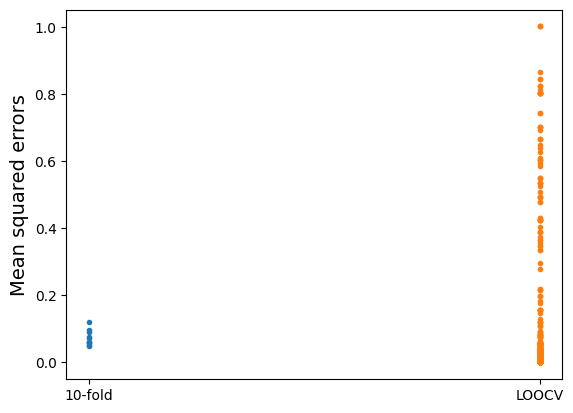

In [ ]:
#Using k-folds cross validation techniques with 10 folds and the LOOCV scores. This is for Logistic Regression

#We define the x and y like this because it had the best correlation

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["EDStations"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

ten_fold_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=10)
#print(ten_fold)

# neg_mean_square_error is the negative MSE, so add a - so the scores are positive.
LOOCV_scores = -cross_val_score(LinearRegression(), X, y, scoring="neg_mean_squared_error", cv=LeaveOneOut())
#print(LOOCV_scores)

# Plot the errors for both scores
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, ".")
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, ".")
plt.ylabel("Mean squared errors", fontsize=14)
plt.xticks([0, 1], ["10-fold", "LOOCV"]);

In [ ]:
# Define X and y

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1
X = data[["ED_Burden"]].values
y = data["TEACHINGDesignation"].astype(int).values

# Split the data, preserving the proportion of Urban/Rural observations
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
logisticModel = LogisticRegression()
logisticModel.fit(X_train, y_train)

# Predict probabilities on the testing data
y_prob = logisticModel.predict_proba(X_test)

# Predict the actual classes (0 or 1)
y_pred = logisticModel.predict(X_test)

# Calculate performance
log_loss = metrics.log_loss(y_test, y_prob)
MAE = metrics.mean_absolute_error(y_test, y_pred)
accuracy = metrics.accuracy_score(y_test, y_pred)

print("Log Loss:", log_loss)
print("Mean Absolute Error:", MAE)
print("Accuracy:", accuracy)

Log Loss: 0.31889135880089475
Mean Absolute Error: 0.09868421052631579
Accuracy: 0.9013157894736842


5. Apply **bootstrap method** to one of the models and report the error mean and standard deviation.

6. Compare models using **one-standard-error** or **adjusted-R-sqaured** methods, and report.

In [ ]:
#Already done in previous tasks with linear and multiple linear regression. Was not done in logistic regression because log loss was too high to
#even consider partially doing it